# Concrete Slump Prediction Using K-Nearest Neighbors (KNN) Regression

In [2]:
import pandas as pd
df = pd.read_csv("uci-slump-test.csv")

df.head()

,No,Cement,Slag,Fly ash,Water,SP,Coarse Aggregate,Fine Aggregate,SLUMP(cm),FLOW(cm),Compressive Strength (28-day)(Mpa)
0,1,273.0,82.0,105.0,210.0,9.0,904.0,680.0,23.0,62.0,34.99
1,2,163.0,149.0,191.0,180.0,12.0,843.0,746.0,0.0,20.0,41.14
2,3,162.0,148.0,191.0,179.0,16.0,840.0,743.0,1.0,20.0,41.81
3,4,162.0,148.0,190.0,179.0,19.0,838.0,741.0,3.0,21.5,42.08
4,5,154.0,112.0,144.0,220.0,10.0,923.0,658.0,20.0,64.0,26.82


In [3]:
df.shape

(103, 11)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 11 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   No                                  103 non-null    int64  
 1   Cement                              103 non-null    float64
 2   Slag                                103 non-null    float64
 3   Fly ash                             103 non-null    float64
 4   Water                               103 non-null    float64
 5   SP                                  103 non-null    float64
 6   Coarse Aggregate                    103 non-null    float64
 7   Fine Aggregate                      103 non-null    float64
 8   SLUMP(cm)                           103 non-null    float64
 9   FLOW(cm)                            103 non-null    float64
 10  Compressive Strength (28-day)(Mpa)  103 non-null    float64
dtypes: float64(10), int64(1)
memory usage: 9.0 KB

In [5]:
df.describe()

,No,Cement,Slag,Fly ash,Water,SP,Coarse Aggregate,Fine Aggregate,SLUMP(cm),FLOW(cm),Compressive Strength (28-day)(Mpa)
count,103.000000,103.000000,103.000000,103.000000,103.000000,103.000000,103.000000,103.000000,103.000000,103.00000,103.000000
mean,52.000000,229.894175,77.973786,149.014563,197.167961,8.539806,883.978641,739.604854,18.048544,49.61068,36.039417
std,29.877528,78.877230,60.461363,85.418080,20.208158,2.807530,88.391393,63.342117,8.750844,17.56861,7.838232
min,1.000000,137.000000,0.000000,0.000000,160.000000,4.400000,708.000000,640.600000,0.000000,20.00000,17.190000
25%,26.500000,152.000000,0.050000,115.500000,180.000000,6.000000,819.500000,684.500000,14.500000,38.50000,30.900000
50%,52.000000,248.000000,100.000000,164.000000,196.000000,8.000000,879.000000,742.700000,21.500000,54.00000,35.520000
75%,77.500000,303.900000,125.000000,235.950000,209.500000,10.000000,952.800000,788.000000,24.000000,63.75000,41.205000
max,103.000000,374.000000,193.000000,260.000000,240.000000,19.000000,1049.900000,902.000000,29.000000,78.00000,58.530000


In [6]:
X = df[['Cement', 'Slag', 'Fly ash', 'Water', 'SP',
        'Coarse Aggregate', 'Fine Aggregate']]

y = df['SLUMP(cm)']

In [7]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (103, 7)
y shape: (103,)


In [9]:
from sklearn.model_selection import train_test_split 
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [10]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (82, 7)
X_test: (21, 7)
y_train: (82,)
y_test: (21,)


In [11]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [12]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(82, 7)
(21, 7)


In [13]:
from sklearn.neighbors import KNeighborsRegressor

In [14]:
knn=KNeighborsRegressor(n_neighbors=5)

In [15]:
knn.fit(X_train_scaled,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [16]:
y_pred=knn.predict(X_test_scaled)

In [17]:
y_pred[:10]

array([22.75, 19.2 , 20.4 , 16.9 , 12.75, 18.25,  4.8 , 18.2 , 21.85,
       21.2 ])

In [18]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison.head(10)

,Actual,Predicted
0,24.0,22.75
1,21.0,19.20
2,25.0,20.40
3,25.0,16.90
4,13.0,12.75
5,2.5,18.25
6,14.5,4.80
7,17.5,18.20
8,24.5,21.85
9,23.0,21.20


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [21]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 4.828571428571429
MSE: 38.78666666666667
RMSE: 6.227894240163899
R2 Score: 0.262591826176927


In [23]:
from sklearn.neighbors import KNeighborsRegressor

metrics = ['minkowski', 'manhattan', 'chebyshev']

for metric in metrics:
    model = KNeighborsRegressor(
        n_neighbors=5,
        metric=metric
    )

    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)

    print("Distance Metric:", metric)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("RMSE:", mean_squared_error(y_test, predictions) ** 0.5)
    print("R2 Score:", r2_score(y_test, predictions))
    print("-" * 40)

Distance Metric: minkowski
MAE: 4.828571428571429
RMSE: 6.227894240163899
R2 Score: 0.262591826176927
----------------------------------------
Distance Metric: manhattan
MAE: 4.557142857142858
RMSE: 5.887921453927443
R2 Score: 0.3409027418520434
----------------------------------------
Distance Metric: chebyshev
MAE: 4.597619047619046
RMSE: 5.899989911210099
R2 Score: 0.33819807294361093
----------------------------------------


In [24]:
knn = KNeighborsRegressor(
    n_neighbors=5,
    metric='manhattan'
)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

In [25]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 4.557142857142858
RMSE: 5.887921453927443
R2 Score: 0.3409027418520434


In [26]:
k_values = range(1, 16)

for k in k_values:
    model = KNeighborsRegressor(
        n_neighbors=k,
        metric='manhattan'
    )

    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)

    rmse = mean_squared_error(y_test, predictions) ** 0.5
    r2 = r2_score(y_test, predictions)

    print("K:", k, "| RMSE:", rmse, "| R2:", r2)

K: 1 | RMSE: 6.507093199329629 | R2: 0.19499321003621306
K: 2 | RMSE: 6.818654384777661 | R2: 0.1160598810139678
K: 3 | RMSE: 5.315321768495817 | R2: 0.4628635684313387
K: 4 | RMSE: 5.763990484857154 | R2: 0.36835654584842203
K: 5 | RMSE: 5.887921453927443 | R2: 0.3409027418520434
K: 6 | RMSE: 5.78786845879347 | R2: 0.3631123990486864
K: 7 | RMSE: 5.567786180729698 | R2: 0.4106265242775847
K: 8 | RMSE: 5.358436723711852 | R2: 0.4541143189423822
K: 9 | RMSE: 5.492616362819479 | R2: 0.42643317733581143
K: 10 | RMSE: 5.42739688108046 | R2: 0.4399734059751681
K: 11 | RMSE: 5.3325046704720345 | R2: 0.45938514085500626
K: 12 | RMSE: 5.3645481775701205 | R2: 0.45286841166939695
K: 13 | RMSE: 5.672698193107202 | R2: 0.38820651782953797
K: 14 | RMSE: 5.700120623414663 | R2: 0.38227727071169904
K: 15 | RMSE: 5.792771677159709 | R2: 0.36203285767661075


In [27]:
knn = KNeighborsRegressor(
    n_neighbors=3,
    metric='manhattan'
)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

In [28]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 4.0476190476190474
MSE: 28.252645502645503
RMSE: 5.315321768495817
R2 Score: 0.4628635684313387


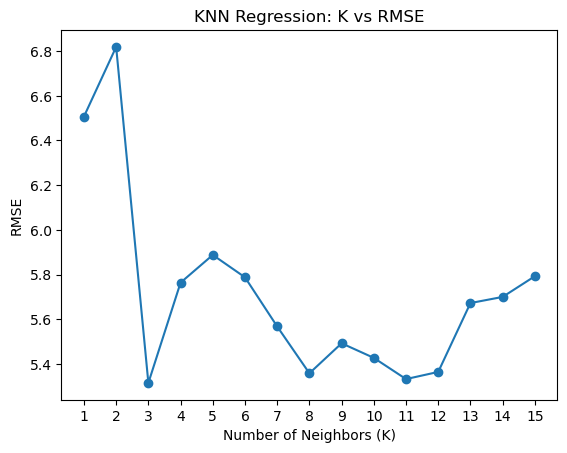

In [29]:
import matplotlib.pyplot as plt

k_values = range(1, 16)
rmse_values = []

for k in k_values:
    model = KNeighborsRegressor(
        n_neighbors=k,
        metric='manhattan'
    )

    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)

    rmse = mean_squared_error(y_test, predictions) ** 0.5
    rmse_values.append(rmse)

plt.plot(k_values, rmse_values, marker='o')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('RMSE')
plt.title('KNN Regression: K vs RMSE')
plt.xticks(list(k_values))
plt.show()

In [30]:
new_data = pd.DataFrame({
    'Cement': [230],
    'Slag': [78],
    'Fly ash': [149],
    'Water': [197],
    'SP': [8.5],
    'Coarse Aggregate': [884],
    'Fine Aggregate': [740]
})

In [31]:
new_data_scaled = scaler.transform(new_data)

In [32]:
new_data_scaled

array([[-0.00277919, -0.01671688,  0.04356324,  0.02827627, -0.0155007 ,
        -0.05026629,  0.01582859]])

In [33]:
new_prediction = knn.predict(new_data_scaled)

print("Predicted Slump Value:", new_prediction[0], "cm")

Predicted Slump Value: 16.166666666666668 cm
